# Solar Filament Instance Segmentation

This notebook presents the final submission workflow: **official data → absorption channels → model and losses → two-stage training or checkpoint loading → D4 instance fusion → COCO RLE export**. Supporting implementations are in `tools/`.

The method uses one Swin-Tiny Mask2Former with native subpixel mask features and multi-expert quality supervision. The supplied checkpoint produced a public score of **0.41**, submission **57456520**, with **1245 instances across 180 TEST images**.

The default configuration loads the supplied weights. Set `TRAIN_FROM_SCRATCH=True` to run the 32-epoch warmup and 12-epoch native stage. Place the official data at the configured path, run `git lfs pull` to retrieve the weights, and execute the cells in order.


## 1. Environment and configuration

Use Python 3.12 and the versions listed in `requirements.txt`. Install them with `python -m pip install -r requirements.txt`, then launch `jupyter lab main.ipynb`. Set the CUDA device and paths below.


In [ ]:
import os
import sys
from pathlib import Path

sys.dont_write_bytecode = True
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
os.environ.setdefault("MPLBACKEND", "Agg")

REPO_ROOT = Path(os.environ.get("SOLAR_REPO_ROOT", Path.cwd())).resolve()
DEVICE = "cuda"
DATA_ROOT = Path(os.environ.get("SOLAR_DATA_ROOT", REPO_ROOT / "MAGFiLO_1.0_Kaggle_2026")).resolve()
CHECKPOINTS_DIR = REPO_ROOT / "checkpoints"
OUTPUT = REPO_ROOT / "results.csv"
TRAIN_FROM_SCRATCH = False
SEED = 16220

sys.path.insert(0, str(REPO_ROOT))
print({"repository": str(REPO_ROOT), "data": str(DATA_ROOT), "device": DEVICE,
       "train_from_scratch": TRAIN_FROM_SCRATCH})


{'repository': '/root/project/kaggle_solar2026/github_code', 'data': '/root/project/kaggle_solar2026/MAGFiLO_1.0_Kaggle_2026', 'device': 'cuda:2', 'train_from_scratch': False}


In [2]:
import gc
import json
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from pycocotools import mask as coco

from tools.checkpoints import completed_checkpoint, load_model_checkpoint, save_model_checkpoint
from tools.reproducibility import runtime_record
from tools.training import seed_expert

device = torch.device(DEVICE)
torch.cuda.set_device(device)
seed_expert(SEED, deterministic=True)
display(runtime_record(device))


{'torch': '2.12.1+cu130',
 'cuda': '13.0',
 'cudnn': 92000,
 'gpu': 'NVIDIA RTX PRO 6000 Blackwell Server Edition',
 'device': 'cuda:2',
 'deterministic_algorithms': True,
 'cudnn_benchmark': False,
 'cudnn_deterministic': True,
 'matmul_tf32': True,
 'cudnn_tf32': True,
 'cublas_workspace': ':4096:8',
 'threads': 8,
 'autocast_dtype': 'bfloat16'}

## 2. Official data and expert versions

The data layout is `DATA_ROOT/train/train_images/*.jpeg`, `DATA_ROOT/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json`, and `DATA_ROOT/test/test_images/*.jpeg`.

TRAIN contains 707 physical images, 1154 expert annotation versions, and 8199 instances. Versions are grouped by image filename. Each expert version forms a sample: its masks supervise instance contours, while all versions for that image contribute to native quality targets. All filament categories share class 0.

The supplied checkpoint supports TEST-only inference. The training stages use the official TRAIN images and annotations.


In [3]:
from tools.data import load_catalog, make_input, preload_images
from tools.training import ExpertDataset

annotation_path = DATA_ROOT / "train/MAGFiLO_1.0_Annotations_kaggle2026_train.json"
test_folder = DATA_ROOT / "test/test_images"
test_names = sorted(path.name for path in test_folder.glob("*.jpeg"))
records = load_catalog(DATA_ROOT) if annotation_path.is_file() else {}
train_names = sorted(records)
if records:
    display({"physical_images": len(records),
             "expert_versions": sum(len(v) for v in records.values()),
             "annotated_instances": sum(len(v["annotations"]) for versions in records.values() for v in versions)})
print("TEST images:", len(test_names))


{'physical_images': 707, 'expert_versions': 1154, 'annotated_instances': 8199}

TEST images: 180


## 3. Absorption representation and augmentation

For grayscale intensity $I\in[0,1]$, construct Gaussian backgrounds $B_{16},B_{64}$ with standard deviations $16S/1024$ and $64S/1024$ at input size $S$:
$$a_{16}=\operatorname{clip}((B_{16}-I)/\max(B_{16},.12),-.3,.3),\quad
a_{64}=\operatorname{clip}((B_{64}-I)/\max(B_{64},.12),-.4,.4).$$
The channels are $[I,.5-2a_{16},.5-1.5a_{64}]$. Set the two contrast channels to .5 where $B_{64}\le .12$, then apply ImageNet mean/std normalization. Images are cached as float16 and converted to float32 before BF16 model execution.

Training applies random D4 transformations and, with probability .5, brightness multiplication/offset and a shared scale factor for the contrast channels. Warmup masks use area interpolation to 256²; native training uses 2048² masks.


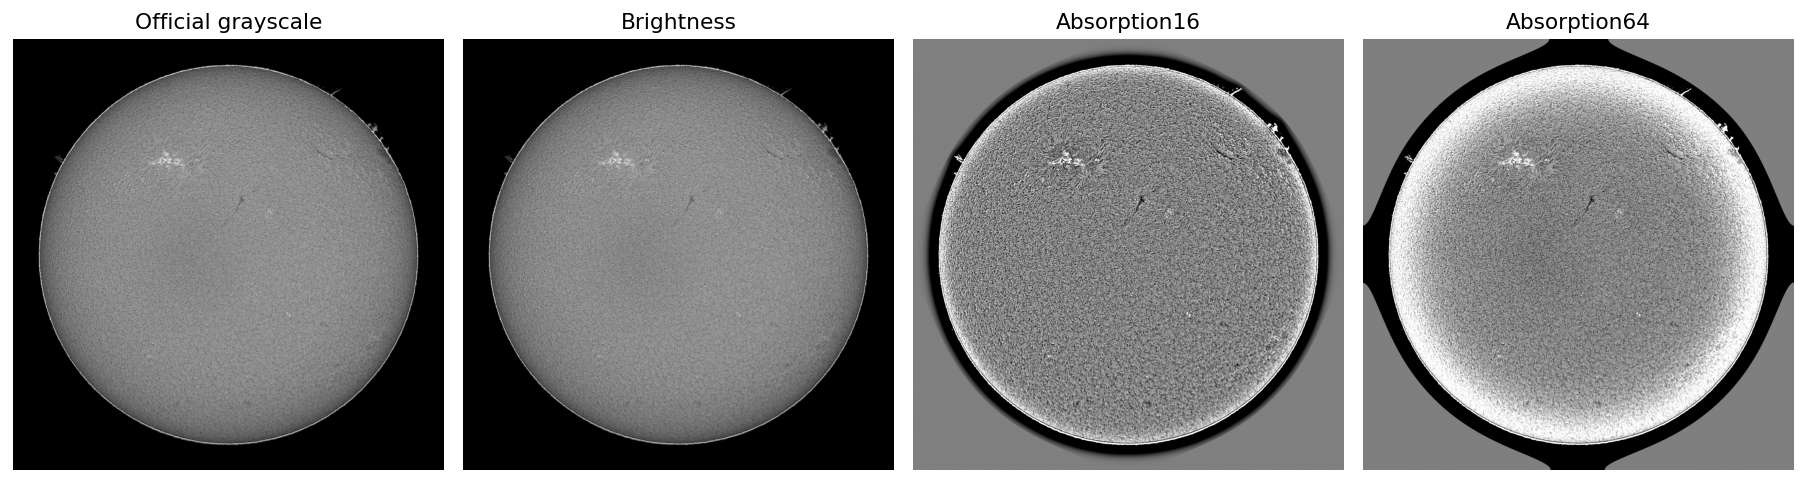

In [4]:
sample_name = test_names[0]
sample_image = cv2.imread(str(test_folder / sample_name), cv2.IMREAD_GRAYSCALE)
sample_channels = make_input(sample_image, 2048)
view_channels = sample_channels.astype(np.float32) * np.array([.229,.224,.225])[:,None,None] + np.array([.485,.456,.406])[:,None,None]
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for axis, image, title in zip(axes, [sample_image, *view_channels], ["Official grayscale", "Brightness", "Absorption16", "Absorption64"]):
    axis.imshow(image, cmap="gray")
    axis.set_title(title)
    axis.axis("off")
fig.tight_layout()
from io import BytesIO
from IPython.display import Image
figure_buffer = BytesIO()
fig.savefig(figure_buffer, format="png", dpi=130, bbox_inches="tight")
display(Image(data=figure_buffer.getvalue()))
plt.close(fig)
del sample_channels, view_channels


## 4. Model construction and foreground marginal

The generic COCO model uses revision `22c4a2f15dc88149b8b8d9f4d42c54431fbd66f6`. Its assets are loaded locally and downloaded when missing.

Swin-Tiny uses channel widths 96/192/384/768, depths 2/2/6/2, and window size 7. The 256-dimensional pixel decoder has 6 deformable-attention layers. The instance decoder uses 100 queries of width 256; its 9 iterative blocks and initial prediction provide 10 supervised outputs.

The original 80 COCO foreground logits are combined with logsumexp, alongside the original empty-object logit. The resulting binary foreground probability equals the sum of the original foreground probabilities.


In [5]:
from tools.native_set_pretrained import read_assets, load_pretrained_model
from tools.set_model import specialize
from tools.native_set_model import attach_native_projection

seed_expert(SEED)
assets = read_assets(CHECKPOINTS_DIR)
model = specialize(load_pretrained_model(assets)).to(device)
del assets
display({"architecture": type(model).__name__, "backbone": model.config.backbone_config.model_type,
         "queries": model.config.num_queries, "hidden_dim": model.config.hidden_dim,
         "warmup_parameters": sum(p.numel() for p in model.parameters()),
         "warmup_criterion": type(model.criterion).__name__})


PRETRAINED_LOCAL /root/project/kaggle_solar2026/github_code/checkpoints/pretrained/mask2former_swin_tiny_coco/config.json


PRETRAINED_LOCAL /root/project/kaggle_solar2026/github_code/checkpoints/pretrained/mask2former_swin_tiny_coco/model.safetensors


Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

PRETRAINED_LOADED Swin-Tiny


{'architecture': 'Mask2FormerForUniversalSegmentation',
 'backbone': 'swin',
 'queries': 100,
 'hidden_dim': 256,
 'warmup_parameters': 47423179,
 'warmup_criterion': 'AreaLoss'}

## 5. Dense set losses and multi-expert utility

Each prediction stage performs Hungarian matching independently. Let $p_i=\sigma(z_i)$, $r_i$ be the foreground probability, $T_j$ the sampled expert's mask, and $\epsilon=hw/2048^2$:
$$C_{ij}=5\operatorname{BCE}(z_i,T_j)+5\left(1-\frac{2\sum p_iT_j+\epsilon}{\sum p_i+\sum T_j+\epsilon}\right)-2r_i.$$
Matched instances receive dense BCE and Dice losses normalized by the batch's ground-truth count. Each stage contributes $L=2L_{class}+5L_{BCE}+5L_{Dice}$; the final and 9 auxiliary losses are summed.

Native training corrects the class probability to $q_i=.1r_i/(1-r_i+.1r_i)$. Pixel ownership uses $\arg\max_iq_ip_i(x)$, followed by a $p_i(x)\ge .5$ threshold for the winning query. Across all expert versions, define $h_{iv}$ as the number of strictly IoU>.5 matches:
$$N_i=\sum_{v,j}\operatorname{IoU}_{ivj}[\operatorname{IoU}_{ivj}>.5],\quad
R_i=\sum_v(h_{iv}+[h_{iv}=0]),\quad t_i=N_i/\max(R_i,1).$$
Every query receives its detached utility target $t_i$. The native classification loss is
$$-\frac{\sum_i[t_i\log r_i+.1(1-t_i)\log(1-r_i)]}{\sum_i[t_i+.1(1-t_i)]}.$$
The $q$ correction inverts the probability shift introduced by background weight .1. Contour supervision uses the expert version selected for the current sample.


## 6. Two-stage training and checkpoints

| Stage | Epochs | Input / mask size | Batch / accumulation | LR / encoder LR |
|---|---:|---|---|---|
| Warmup | 32 | 1024 / 256 | 4 / 1 | 2e-4 / 6e-5 |
| Native | 12 | 2048 / 2048 | 1 / 2 | 1e-4 / 3e-5 |

Both stages use AdamW. Scalars, vectors, and embedder parameters have zero weight decay; the remaining parameters use .05. Each stage starts a new optimizer with 300 warmup updates and cosine decay. Gradient clipping is 1, the seed is 16220, and the data loader uses 4 workers.

Deterministic CUDA settings and the bilinear-sampling backward implementation are in `tools/reproducibility.py`; TF32 remains enabled. Completed stage weights are reused. Setting `TRAIN_FROM_SCRATCH=True` selects `checkpoints/retrained/` for newly trained weights.


In [6]:
from tools.training import train_stage

stage_folder = CHECKPOINTS_DIR / ("retrained" if TRAIN_FROM_SCRATCH else "expert_set_deterministic")
scope = dict(recipe="expert-set-32warm12native-deterministic-v2", seed=SEED)
warmup_path = stage_folder / "warmup_final.pt"
native_path = stage_folder / "native_final.pt"
warmup_metadata = dict(scope, stage="warmup", epochs=32)
native_metadata = dict(scope, stage="native", epochs=12)
native_ready = completed_checkpoint(native_path)
print({"weights_directory": str(stage_folder), "completed_native_available": native_ready})


{'weights_directory': '/root/project/kaggle_solar2026/github_code/checkpoints/expert_set_deterministic', 'completed_native_available': True}


### 6.1 Warmup

A completed native checkpoint skips warmup training. Otherwise, load the warmup checkpoint or train for 32 epochs over all expert-version samples.


In [7]:
if native_ready:
    print("Warmup training skipped: completed native checkpoint is available.")
elif completed_checkpoint(warmup_path):
    load_model_checkpoint(model, warmup_path, device)
else:
    warm_images = preload_images(DATA_ROOT, train_names, 1024)
    warm_dataset = ExpertDataset(train_names, records, warm_images, 1024)
    train_stage(model, warm_dataset, SEED, deterministic=True,
                history_path=stage_folder / "warmup_history.json")
    save_model_checkpoint(model, warmup_path, dict(warmup_metadata, runtime=runtime_record(device),
                          training_history=model._expert_training_history))
    del warm_images, warm_dataset
gc.collect()
torch.cuda.empty_cache()


Warmup training skipped: completed native checkpoint is available.


### 6.2 Native subpixel features and training

Append a 256→4096 pointwise convolution and PixelShuffle(4) after the original mask projection. The 1,052,672 added parameters initially copy coarse features into subpixels, then learn their individual combinations. The resulting 256×2048×2048 features combine with query embeddings to predict native masks. The final model contains 48,475,851 parameters.

Native training supervises contours with the sampled expert and quality with all experts for that image.


In [8]:
seed_expert(SEED, deterministic=True)
attach_native_projection(model)
if native_ready:
    load_model_checkpoint(model, native_path, device)
else:
    native_images = preload_images(DATA_ROOT, train_names, 2048)
    native_dataset = ExpertDataset(train_names, records, native_images, 2048, native=True)
    train_stage(model, native_dataset, SEED, native=True, deterministic=True,
                history_path=stage_folder / "native_history.json")
    save_model_checkpoint(model, native_path, dict(native_metadata, runtime=runtime_record(device),
                          training_history=model._expert_training_history))
    del native_images, native_dataset
model.eval()
gc.collect()
torch.cuda.empty_cache()
display({"parameters": sum(p.numel() for p in model.parameters()),
         "native_criterion": type(model.criterion).__name__, "checkpoint": str(native_path)})


CHECKPOINT_LOADED /root/project/kaggle_solar2026/github_code/checkpoints/expert_set_deterministic/native_final.pt


{'parameters': 48475851,
 'native_criterion': 'ExpertUtilityLoss',
 'checkpoint': '/root/project/kaggle_solar2026/github_code/checkpoints/expert_set_deterministic/native_final.pt'}

## 7. D4 inference and instance fusion

Run the same model for four rotations, followed by four rotated/reflected views, and map each probability field back to the original coordinates.

Each instance group accumulates $F_g=\sum_vq_{gv}p_{gv}$ and $S_g=\sum_vq_{gv}$. Hungarian association uses prototype-mask IoU>.5 and affinity $\operatorname{IoU}\sqrt{q_{prefix}q_{new}}$. Each group receives at most one candidate per view. A missing view contributes zero quality. Final group values are $Q_g=\sum_vq_{gv}/8$ and $P_g=F_g/S_g$.

Keep groups with $Q_g>.225$. Assign each pixel to the largest accumulated field, then retain it when that group's $P_g\ge .5$. The fixed threshold .225 comes from the design target .45/2. Group order, accumulation precision, and pixel competition follow this sequence throughout inference.


In [9]:
from tools.expert_set_orbit import VIEWS, transform, native_fields, OrbitAccumulator

@torch.no_grad()
def predict_image(name, channels):
    tensor = torch.from_numpy(channels.astype(np.float32))[None].to(device)
    accumulator = OrbitAccumulator()
    for turns, reflected in VIEWS:
        values = transform(tensor, turns, reflected).contiguous()
        with torch.inference_mode(), torch.autocast(device.type, dtype=torch.bfloat16):
            output = model(pixel_values=values, output_auxiliary_logits=False)
        probabilities, utilities = native_fields(output, turns, reflected)
        accumulator.add(probabilities, utilities)
        del output, values, probabilities, utilities
    return accumulator.result()

print("Ordered D4 views:", VIEWS)


Ordered D4 views: [(0, False), (1, False), (2, False), (3, False), (0, True), (1, True), (2, True), (3, True)]


## 8. Full TEST inference and CSV export

Run inference on each TEST image and write `results.csv`. Each row contains `filament_id,segmentation_rle`: an image stem with its instance number, and a compressed COCO RLE string in column-major order. Predictions use the original 2048×2048 coordinates.


In [ ]:
from tools.instance_submission import generate_instance_submission

result = generate_instance_submission(predict_image, DATA_ROOT, OUTPUT)
display(result)


## 9. Submission preview

Display a few exported instance identifiers and their RLE lengths.


In [10]:
import csv
from itertools import islice

with OUTPUT.open(newline="") as stream:
    preview = [{"filament_id": row["filament_id"], "rle_length": len(row["segmentation_rle"])}
               for row in islice(csv.DictReader(stream), 5)]
display(preview)
print("CSV:", OUTPUT)


[{'filament_id': '20110120105534Ch_1', 'rle_length': 326},
 {'filament_id': '20110120105534Ch_2', 'rle_length': 260},
 {'filament_id': '20110130110334Ch_1', 'rle_length': 445},
 {'filament_id': '20110214175414Mh_1', 'rle_length': 490},
 {'filament_id': '20110214175414Mh_2', 'rle_length': 256}]

CSV: /root/project/kaggle_solar2026/github_code/results.csv


## 10. Prediction visualization

Decode the first image's instances from the generated CSV and overlay them on the original image.


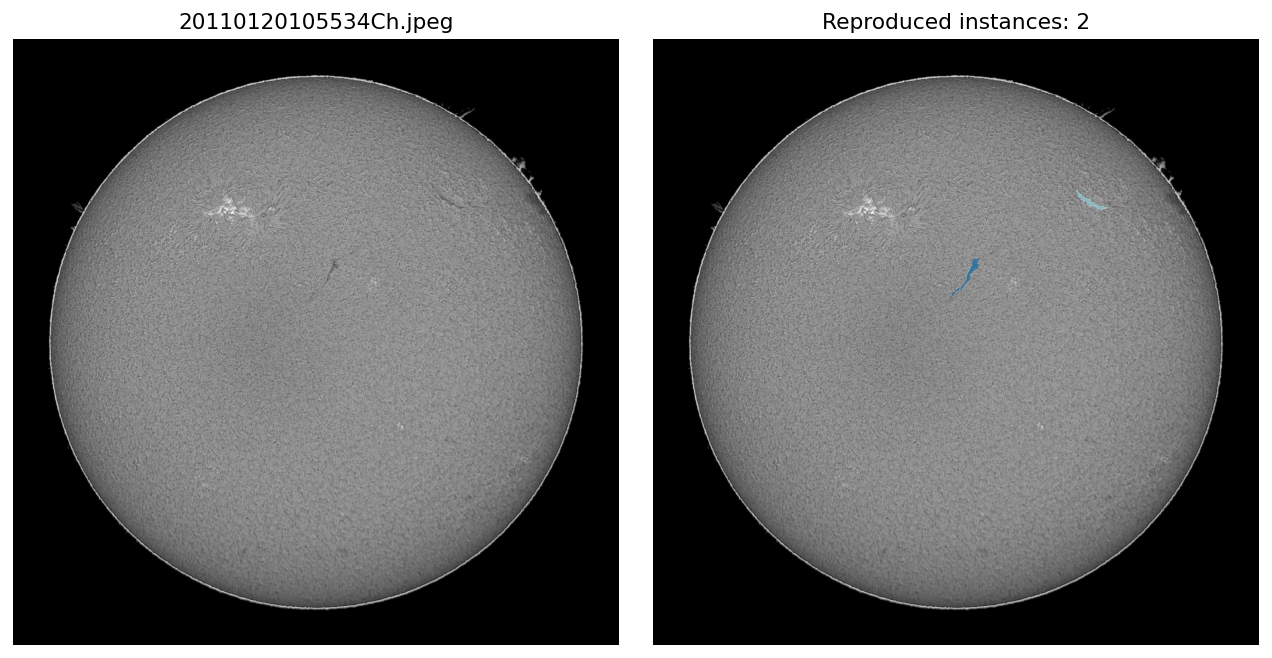

In [11]:
import csv

labels = np.zeros((2048, 2048), dtype=np.int32)
prefix = Path(sample_name).stem + "_"
with OUTPUT.open(newline="") as stream:
    for row in csv.DictReader(stream):
        if not row["filament_id"].startswith(prefix):
            continue
        identifier = int(row["filament_id"].rsplit("_", 1)[1])
        binary = coco.decode({"size": [2048,2048], "counts": row["segmentation_rle"].encode("ascii")}).astype(bool)
        labels[binary] = identifier
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(sample_image, cmap="gray")
axes[0].set_title(sample_name)
axes[1].imshow(sample_image, cmap="gray")
axes[1].imshow(np.ma.masked_equal(labels, 0), cmap="tab20", alpha=.7, interpolation="nearest")
axes[1].set_title(f"Reproduced instances: {labels.max()}")
for axis in axes:
    axis.axis("off")
fig.tight_layout()
from io import BytesIO
from IPython.display import Image
figure_buffer = BytesIO()
fig.savefig(figure_buffer, format="png", dpi=130, bbox_inches="tight")
display(Image(data=figure_buffer.getvalue()))
plt.close(fig)
del labels, sample_image
